# Assignment 11: Matplotlib (Core Plot Types & Visualization)

Dataset used: Kaggle Sample Superstore Sales Dataset (`superstore.csv`).  
All visualizations use `matplotlib.pyplot` directly without Seaborn or Pandas plotting.

### Task 1: Line Plot (Sales Trend)

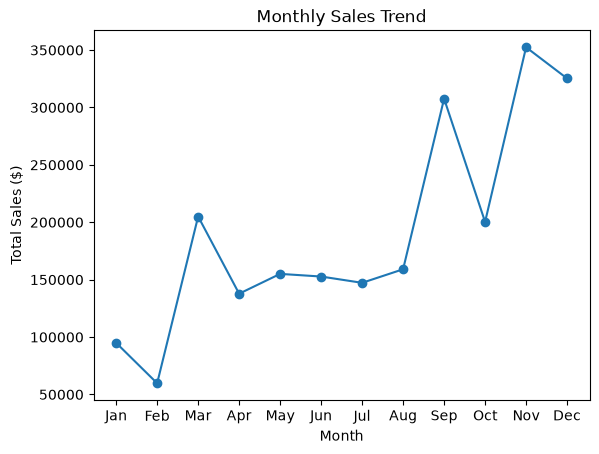

In [1]:
import csv
from collections import defaultdict
import matplotlib.pyplot as plt

# Load the Kaggle Superstore Sales dataset
with open("superstore.csv", mode="r", encoding="utf-8") as file:
    orders = list(csv.DictReader(file))

# Aggregate total sales by month (1 to 12)
monthly_totals = defaultdict(float)
for row in orders:
    month_num = int(row["Order Date"].split("/")[0])
    monthly_totals[month_num] += float(row["Sales"])

month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
monthly_sales = [monthly_totals[m] for m in range(1, 13)]

# Create line plot
plt.plot(month_names, monthly_sales, marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales ($)")
plt.show()

### Task 2: Scatter Plot

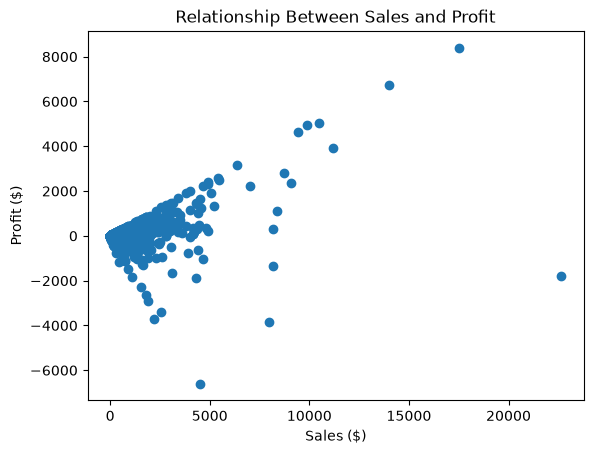

In [2]:
sales_values = [float(row["Sales"]) for row in orders]
profit_values = [float(row["Profit"]) for row in orders]

# Create scatter plot showing relationship between Sales and Profit
plt.scatter(sales_values, profit_values)
plt.title("Relationship Between Sales and Profit")
plt.xlabel("Sales ($)")
plt.ylabel("Profit ($)")
plt.show()

### Task 3: Bar Plot (Vertical & Horizontal)

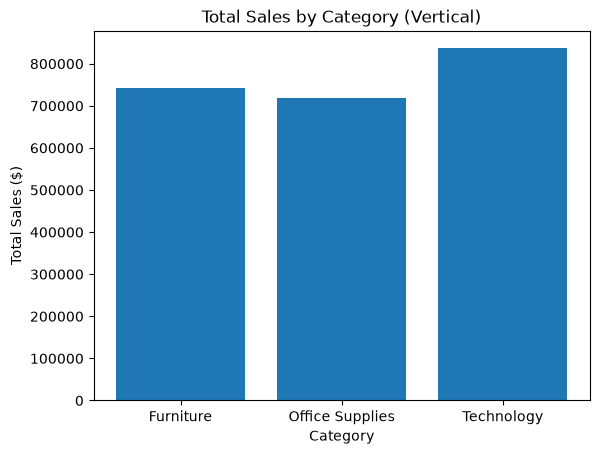

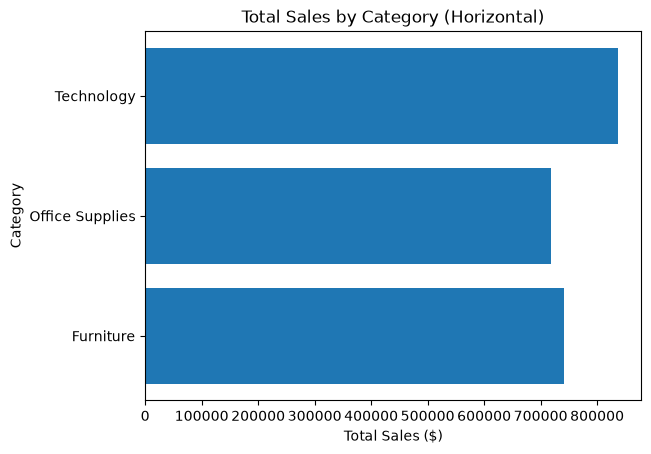

In [3]:
category_totals = defaultdict(float)
for row in orders:
    category_totals[row["Category"]] += float(row["Sales"])

categories = sorted(category_totals.keys())
category_sales = [category_totals[cat] for cat in categories]

# 1. Vertical bar chart
plt.bar(categories, category_sales)
plt.title("Total Sales by Category (Vertical)")
plt.xlabel("Category")
plt.ylabel("Total Sales ($)")
plt.show()

# 2. Horizontal bar chart for the same data
plt.barh(categories, category_sales)
plt.title("Total Sales by Category (Horizontal)")
plt.xlabel("Total Sales ($)")
plt.ylabel("Category")
plt.show()

### Task 4: Multiple Bar Plot

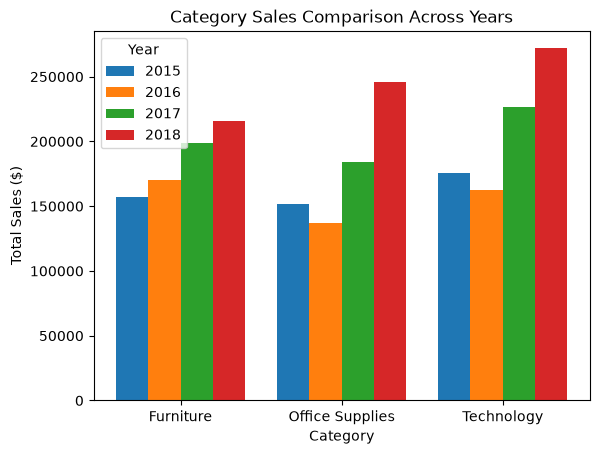

In [4]:
yearly_category_sales = defaultdict(lambda: defaultdict(float))
for row in orders:
    year = row["Order Date"].split("/")[-1]
    category = row["Category"]
    yearly_category_sales[year][category] += float(row["Sales"])

years = sorted(yearly_category_sales.keys())
x = list(range(len(categories)))
width = 0.2

# Plot grouped bars with proper width and alignment
for idx, year in enumerate(years):
    offset = (idx - (len(years) - 1) / 2) * width
    positions = [pos + offset for pos in x]
    values = [yearly_category_sales[year][cat] for cat in categories]
    plt.bar(positions, values, width=width, label=year)

plt.xticks(x, categories)
plt.title("Category Sales Comparison Across Years")
plt.xlabel("Category")
plt.ylabel("Total Sales ($)")
plt.legend(title="Year")
plt.show()

### Task 5: Stacked Bar Chart

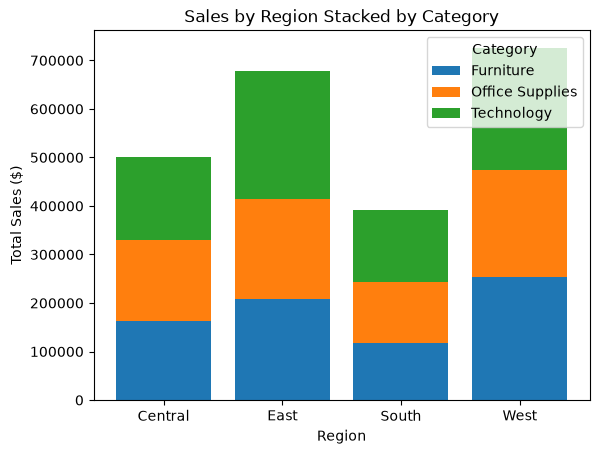

In [5]:
region_category_sales = defaultdict(lambda: defaultdict(float))
for row in orders:
    region_category_sales[row["Region"]][row["Category"]] += float(row["Sales"])

regions = sorted(region_category_sales.keys())
bottom_values = [0.0] * len(regions)

# Stack each category on top of the previous categories per region
for cat in categories:
    values = [region_category_sales[reg][cat] for reg in regions]
    plt.bar(regions, values, bottom=bottom_values, label=cat)
    bottom_values = [b + v for b, v in zip(bottom_values, values)]

plt.title("Sales by Region Stacked by Category")
plt.xlabel("Region")
plt.ylabel("Total Sales ($)")
plt.legend(title="Category")
plt.show()

### Task 6: Histogram (Numeric Distribution)

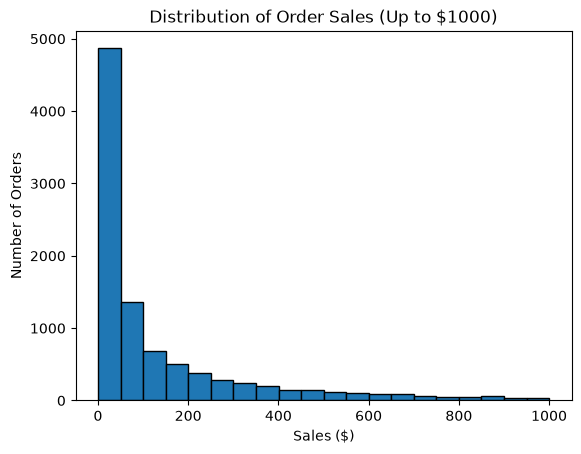

In [6]:
# Focus on orders up to $1000 (>95% of orders) so the distribution bins are clear
filtered_sales = [s for s in sales_values if s <= 1000]

plt.hist(filtered_sales, bins=20, edgecolor="black")
plt.title("Distribution of Order Sales (Up to $1000)")
plt.xlabel("Sales ($)")
plt.ylabel("Number of Orders")
plt.show()

### Task 7: Pie Chart (Market Share)

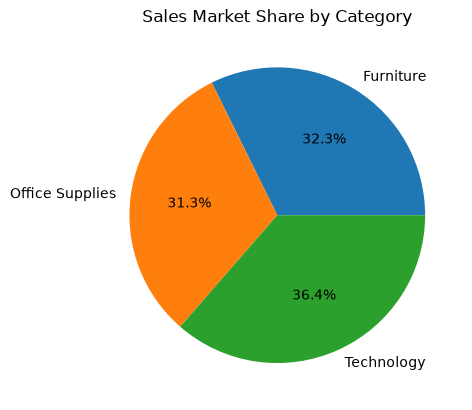

In [7]:
plt.pie(category_sales, labels=categories, autopct="%1.1f%%")
plt.title("Sales Market Share by Category")
plt.show()